# Kazakh Steppes — analysis notebook (v3, matches the published AIST 2026 paper)

Uses the data exported by `full_pipeline.js` (v3: reflectance scaled before computing EVI, points exported with coordinates).

**Inputs:** upload `betpak_samples_v3.csv` and `zhanaarka_samples_v3.csv` to the main Colab folder, then *Runtime → Run all* (~20–30 min on free Colab because of the grid search).

**Sections:** 1. load + sanity checks (EVI clipped to [−1, 1]) · 3. reproduce the original numbers · 4. built-up leakage check · 5. spatial block CV · 6. SHAP · 7. distance trend · 8. summary · 9. every number and Figures 1–4 of the paper.

In [3]:
!pip install shap -q
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
                                     StratifiedGroupKFold, cross_val_score, cross_val_predict)
from sklearn.metrics import accuracy_score, f1_score, classification_report
from xgboost import XGBClassifier
warnings.filterwarnings('ignore')

DATA = ''   # CSVs uploaded to the main Colab folder
SPEC = ['BSI', 'EVI', 'NDVI', 'NDWI']
SPEC_D = SPEC + ['dist_settlement']
SEED = 42

# Numbers reported in the submitted paper / README (accuracy, %)
PAPER = {
    'betpak_rf_4f_split': 66.47, 'betpak_rf_5f_split': 74.25,
    'betpak_rf_4f_rcv': 64.33,   'betpak_rf_5f_rcv': 72.60,
    'betpak_xgb_4f_split': 66.71, 'betpak_svm_unscaled_4f_split': 56.38,
    'zh_rf_cv': 64.83, 'zh_xgb_cv': 64.38, 'zh_svm_std_cv': 62.08,
}
R = {}   # rerun results go here

## 1. Load data and sanity checks

In [4]:
def load(path):
    df = pd.read_csv(path)
    geo = df['.geo'].apply(json.loads)
    df['lon'] = geo.apply(lambda g: g['coordinates'][0] if g['coordinates'] else np.nan)
    df['lat'] = geo.apply(lambda g: g['coordinates'][1] if g['coordinates'] else np.nan)
    return df.drop(columns=['system:index', '.geo'])

bp = load(DATA + 'betpak_samples_v3.csv')
zh = load(DATA + 'zhanaarka_samples_v3.csv')
zh = zh[zh['label'] != 100].reset_index(drop=True)   # same as paper: class 100 has 1 sample

for name, d in [('Betpak-Dala', bp), ('Zhanaarka', zh)]:
    print(f'=== {name}: {len(d)} rows, missing coords: {d.lon.isna().sum()}')
    print(d['label'].value_counts().sort_index().to_dict())
    print(d[SPEC].describe().loc[['min', 'max']].round(3), '\n')

assert bp.lon.notna().all(), 'No coordinates'
for name, d in [('Betpak-Dala', bp), ('Zhanaarka', zh)]:
    bad = ~d['EVI'].between(-1, 1)
    print(f'{name}: {bad.sum()} points with EVI outside [-1, 1]; by class:',
          d.loc[bad, 'label'].value_counts().to_dict())
    d['EVI'] = d['EVI'].clip(-1, 1)
print('EVI clipped to [-1, 1]')

=== Betpak-Dala: 4308 rows, missing coords: 0
{10: 500, 20: 500, 30: 500, 40: 500, 50: 500, 60: 500, 80: 500, 90: 500, 100: 308}
       BSI      EVI   NDVI   NDWI
min -0.602 -286.154 -0.694 -0.800
max  0.268  141.604  0.879  0.865 

=== Zhanaarka: 4000 rows, missing coords: 0
{10: 500, 20: 500, 30: 500, 40: 500, 50: 500, 60: 500, 80: 500, 90: 500}
       BSI    EVI   NDVI   NDWI
min -0.394 -0.735 -0.724 -0.800
max  0.349  0.749  0.887  0.803 

Betpak-Dala: 281 points with EVI outside [-1, 1]; by class: {80: 281}
Zhanaarka: 0 points with EVI outside [-1, 1]; by class: {}
EVI clipped to [-1, 1]


In [5]:
# Optional: compare with the old export. If the same points were drawn, NDVI/BSI/NDWI/dist must be identical
# and only EVI should differ.
import os
if os.path.exists(DATA + 'betpak_samples_v2.csv'):
    old = pd.read_csv(DATA + 'betpak_samples_v2.csv').drop(columns=['system:index', '.geo'])
    if len(old) == len(bp) and (old['label'].values == bp['label'].values).all():
        for c in ['NDVI', 'BSI', 'NDWI', 'dist_settlement', 'EVI']:
            print(f'{c:16s} max abs diff old vs new: {np.abs(old[c].values - bp[c].values).max():.6f}')
        print('Expected: ~0 for all except EVI.')
    else:
        print('Different points were sampled than in v2 — results are still comparable, just not row-by-row.')
else:
    print('betpak_samples_v2.csv not uploaded; skipping row-by-row check.')

betpak_samples_v2.csv not uploaded; skipping row-by-row check.


## 2. Helpers

In [6]:
def rf():  return RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
def xgb(): return XGBClassifier(random_state=SEED, eval_metric='mlogloss', n_jobs=-1)
def svm_unscaled(): return SVC(random_state=SEED)
def svm_std(): return Pipeline([('s', StandardScaler()), ('svm', SVC(random_state=SEED))])

def Xy(d, feats):
    return d[feats].values, LabelEncoder().fit_transform(d['label'])

def split_acc(model, d, feats):
    X, y = Xy(d, feats)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
    return 100 * accuracy_score(yte, model.fit(Xtr, ytr).predict(Xte))

def rcv_acc(model, d, feats):
    X, y = Xy(d, feats)
    s = cross_val_score(model, X, y, cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED))
    return 100 * s.mean(), 100 * s.std()

def blocks(d, deg):
    return (np.floor(d.lon / deg)).astype(int).astype(str) + '_' + (np.floor(d.lat / deg)).astype(int).astype(str)

def spatial_cv(model, d, feats, deg=0.5):
    """5-fold spatial block CV: whole grid cells of `deg` degrees are held out together."""
    X, y = Xy(d, feats)
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    pred = cross_val_predict(model, X, y, cv=cv, groups=blocks(d, deg))
    return 100 * accuracy_score(y, pred), f1_score(y, pred, average=None)

## 3. Reproduce the paper's numbers with fixed EVI (random splits, as in the paper)

In [7]:
R['betpak_rf_4f_split'] = split_acc(rf(), bp, SPEC)
R['betpak_rf_5f_split'] = split_acc(rf(), bp, SPEC_D)
R['betpak_rf_4f_rcv'], _ = rcv_acc(rf(), bp, SPEC)
R['betpak_rf_5f_rcv'], _ = rcv_acc(rf(), bp, SPEC_D)
R['betpak_xgb_4f_split'] = split_acc(xgb(), bp, SPEC)
R['betpak_svm_unscaled_4f_split'] = split_acc(svm_unscaled(), bp, SPEC)

Xz, yz = Xy(zh, SPEC_D)
cv5 = StratifiedKFold(n_splits=5, shuffle=False)   # paper used cv=5 (unshuffled)
R['zh_rf_cv'] = 100 * cross_val_score(rf(), Xz, yz, cv=cv5).mean()
R['zh_xgb_cv'] = 100 * cross_val_score(xgb(), Xz, yz, cv=cv5).mean()
R['zh_svm_std_cv'] = 100 * cross_val_score(svm_std(), Xz, yz, cv=cv5).mean()

for k in PAPER:
    print(f'{k:30s} paper {PAPER[k]:6.2f}   rerun {R[k]:6.2f}   diff {R[k]-PAPER[k]:+6.2f}')

betpak_rf_4f_split             paper  66.47   rerun  67.98   diff  +1.51
betpak_rf_5f_split             paper  74.25   rerun  73.32   diff  -0.93
betpak_rf_4f_rcv               paper  64.33   rerun  65.51   diff  +1.18
betpak_rf_5f_rcv               paper  72.60   rerun  72.75   diff  +0.15
betpak_xgb_4f_split            paper  66.71   rerun  66.24   diff  -0.47
betpak_svm_unscaled_4f_split   paper  56.38   rerun  56.73   diff  +0.35
zh_rf_cv                       paper  64.83   rerun  66.68   diff  +1.85
zh_xgb_cv                      paper  64.38   rerun  65.55   diff  +1.17
zh_svm_std_cv                  paper  62.08   rerun  64.28   diff  +2.20


## 4. Built-up leakage check: ablation without class 50 (random repeated CV)

In [8]:
bp_no50 = bp[bp.label != 50].reset_index(drop=True)
bp_no50_100 = bp[~bp.label.isin([50, 100])].reset_index(drop=True)

for name, d in [('all classes', bp), ('without 50', bp_no50), ('without 50 & 100', bp_no50_100)]:
    a4, _ = rcv_acc(rf(), d, SPEC); a5, _ = rcv_acc(rf(), d, SPEC_D)
    R[f'gain_rcv_{name}'] = a5 - a4
    print(f'{name:18s} 4f {a4:6.2f}  5f {a5:6.2f}  gain {a5-a4:+6.2f} pp')

all classes        4f  65.51  5f  72.75  gain  +7.23 pp
without 50         4f  67.53  5f  71.22  gain  +3.69 pp
without 50 & 100   4f  69.49  5f  71.84  gain  +2.35 pp


## 5. Spatial block CV (the honest estimate)

Points in the same grid cell are always in the same fold, so the model is tested on areas it never saw.
Three block sizes to show sensitivity (~0.25° ≈ 25 km, 0.5° ≈ 50 km, 1° ≈ 100 km).

In [9]:
rows = []
for deg in [0.25, 0.5, 1.0]:
    for name, d in [('all classes', bp), ('without 50', bp_no50)]:
        a4, f4 = spatial_cv(rf(), d, SPEC, deg)
        a5, f5 = spatial_cv(rf(), d, SPEC_D, deg)
        rows.append({'block_deg': deg, 'classes': name, 'acc_4f': a4, 'acc_5f': a5, 'gain_pp': a5 - a4})
        if deg == 0.5:
            R[f'spatial_4f_{name}'], R[f'spatial_5f_{name}'] = a4, a5
            if name == 'all classes':
                classes = sorted(d.label.unique())
                print('Per-class F1, spatial CV 0.5°, all classes:')
                print(pd.DataFrame({'4 features': f4, '5 features': f5}, index=classes).round(2).T, '\n')
spatial = pd.DataFrame(rows).round(2)
spatial

Per-class F1, spatial CV 0.5°, all classes:
             10    20    30    40    50    60    80    90    100
4 features  0.71  0.47  0.46  0.60  0.64  0.67  0.95  0.44  0.27
5 features  0.72  0.49  0.44  0.62  0.89  0.70  0.95  0.58  0.41 



,block_deg,classes,acc_4f,acc_5f,gain_pp
0,0.25,all classes,60.93,67.32,6.38
1,0.25,without 50,60.50,61.55,1.05
2,0.50,all classes,59.70,65.58,5.87
3,0.50,without 50,56.30,59.43,3.12
4,1.00,all classes,50.72,56.94,6.22
5,1.00,without 50,50.71,53.31,2.60


## 6. SHAP rerun (5-feature RF, Betpak-Dala, same split as paper)

In [10]:
import shap
X2, y2 = Xy(bp, SPEC_D)
le2 = LabelEncoder().fit(bp['label'])
Xtr, Xte, ytr, yte = train_test_split(X2, y2, test_size=0.2, random_state=SEED, stratify=y2)
m = rf().fit(Xtr, ytr)
sv = shap.TreeExplainer(m).shap_values(Xte)
sv = np.stack(sv, axis=-1) if isinstance(sv, list) else sv          # -> (n, features, classes)

glob = pd.Series(np.abs(sv).mean(axis=(0, 2)), index=SPEC_D).sort_values(ascending=False)
c60 = list(le2.classes_).index(60)
cls60 = pd.Series(np.abs(sv[:, :, c60]).mean(axis=0), index=SPEC_D).sort_values(ascending=False)
R['shap_global_rank'] = list(glob.index); R['shap_c60_rank'] = list(cls60.index)
print('Global mean |SHAP| :', glob.round(4).to_dict())
print('Class 60 mean |SHAP|:', cls60.round(4).to_dict())
print('Paper: global rank 1 = dist_settlement; class 60 order = NDVI, EVI, NDWI, dist_settlement, BSI')

Global mean |SHAP| : {'NDVI': 0.0598, 'NDWI': 0.0514, 'dist_settlement': 0.0506, 'BSI': 0.0329, 'EVI': 0.0195}
Class 60 mean |SHAP|: {'NDVI': 0.1052, 'NDWI': 0.0506, 'dist_settlement': 0.0411, 'BSI': 0.0257, 'EVI': 0.0133}
Paper: global rank 1 = dist_settlement; class 60 order = NDVI, EVI, NDWI, dist_settlement, BSI


## 7. Distance trend (Zhanaarka) — should be unchanged (uses NDVI/BSI only)

In [11]:
zh_all = load(DATA + 'zhanaarka_samples_v3.csv')
bins = [0, 1000, 2000, 5000, 10000, 20000, max(zh_all['dist_settlement'].max(), 20001)]
lbl = ['0-1km', '1-2km', '2-5km', '5-10km', '10-20km', '20km+']
zh_all['dist_bin'] = pd.cut(zh_all['dist_settlement'], bins=bins, labels=lbl)
trend = zh_all.groupby('dist_bin', observed=False)[['NDVI', 'BSI']].mean().round(3)
print(trend)
print('Paper NDVI: 0.326 0.344 0.286 0.229 0.216 0.129')
# Same trend without built-up pixels (does the reversed piosphere survive?)
print(zh_all[zh_all.label != 50].groupby('dist_bin', observed=False)[['NDVI', 'BSI']].mean().round(3))

           NDVI    BSI
dist_bin              
0-1km     0.326 -0.004
1-2km     0.344  0.028
2-5km     0.286  0.045
5-10km    0.229  0.085
10-20km   0.216  0.104
20km+     0.129  0.138
Paper NDVI: 0.326 0.344 0.286 0.229 0.216 0.129
           NDVI    BSI
dist_bin              
0-1km     0.331 -0.010
1-2km     0.345  0.027
2-5km     0.286  0.044
5-10km    0.229  0.085
10-20km   0.216  0.104
20km+     0.129  0.138


## 8. Summary and verdict

In [12]:
print('=== PAPER vs RERUN ===')
for k in PAPER:
    print(f'{k:30s} {PAPER[k]:6.2f} -> {R[k]:6.2f} ({R[k]-PAPER[k]:+.2f})')

evi_shift = max(abs(R[k] - PAPER[k]) for k in PAPER)
g_spatial_no50 = R['spatial_5f_without 50'] - R['spatial_4f_without 50']
print(f'''
Claim 0 (numbers in paper still valid after EVI fix): max change {evi_shift:.2f} pp
   -> {'MINOR (<2 pp): no need to change numbers' if evi_shift < 2 else 'NOTABLE (>=2 pp): update tables'}
Claim 1 (dist_settlement improves accuracy):
   random CV gain all classes  {R['gain_rcv_all classes']:+.2f} pp | without class 50 {R['gain_rcv_without 50']:+.2f} pp
   spatial CV gain without 50  {g_spatial_no50:+.2f} pp
   -> {'HOLDS' if g_spatial_no50 >= 2 else 'WEAK (0-2 pp): soften the claim' if g_spatial_no50 > 0 else 'DOES NOT HOLD under honest evaluation'}
Claim 2 (SHAP): global top = {R['shap_global_rank'][0]} | class 60 order = {R['shap_c60_rank']}
Spatial vs random accuracy (5f, all classes): {R['spatial_5f_all classes']:.2f} vs {R['betpak_rf_5f_rcv']:.2f}
   -> optimism from random CV: {R['betpak_rf_5f_rcv'] - R['spatial_5f_all classes']:.2f} pp
''')

=== PAPER vs RERUN ===
betpak_rf_4f_split              66.47 ->  67.98 (+1.51)
betpak_rf_5f_split              74.25 ->  73.32 (-0.93)
betpak_rf_4f_rcv                64.33 ->  65.51 (+1.18)
betpak_rf_5f_rcv                72.60 ->  72.75 (+0.15)
betpak_xgb_4f_split             66.71 ->  66.24 (-0.47)
betpak_svm_unscaled_4f_split    56.38 ->  56.73 (+0.35)
zh_rf_cv                        64.83 ->  66.68 (+1.85)
zh_xgb_cv                       64.38 ->  65.55 (+1.17)
zh_svm_std_cv                   62.08 ->  64.28 (+2.20)

Claim 0 (numbers in paper still valid after EVI fix): max change 2.20 pp
   -> NOTABLE (>=2 pp): update tables
Claim 1 (dist_settlement improves accuracy):
   random CV gain all classes  +7.23 pp | without class 50 +3.69 pp
   spatial CV gain without 50  +3.12 pp
   -> HOLDS
Claim 2 (SHAP): global top = NDVI | class 60 order = ['NDVI', 'NDWI', 'dist_settlement', 'BSI', 'EVI']
Spatial vs random accuracy (5f, all classes): 65.58 vs 72.75
   -> optimism from random CV: 7

## 9. All numbers and figures for the corrected paper

Computes every number the paper reports, with the corrected data, and redraws Figures 1–4 in the **same style and size**
as the originals. At the end it zips the figures: download `paper_figures_v3.zip` from the Files panel
and send it together with this executed notebook. The grid search takes ~10–20 minutes.

In [13]:
QUICK_TEST = False   # leave False
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV
import shap, zipfile
NUMS = {}
CLASSES = sorted(bp.label.unique())
NAMES = {10:'Tree cover', 20:'Shrubland', 30:'Grassland', 40:'Cropland', 50:'Built-up',
         60:'Bare/sparse', 80:'Water', 90:'Wetland', 100:'Moss/lichen'}

def svm_scaled(): return Pipeline([('s', StandardScaler()), ('svm', SVC(random_state=SEED))])

def split_eval(model, d, feats):
    X, y = Xy(d, feats)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
    m = model.fit(Xtr, ytr); p = m.predict(Xte)
    return dict(acc=100*accuracy_score(yte, p), wf1=f1_score(yte, p, average='weighted'),
                mf1=f1_score(yte, p, average='macro'), perclass=f1_score(yte, p, average=None)), m, Xte, yte, p

print('=== A. Betpak-Dala single 80/20 split ===')
for feats, tag in [(SPEC, '4f'), (SPEC_D, '5f')]:
    for mname, mk in [('RF', rf), ('XGB', xgb), ('SVM_scaled', svm_scaled), ('SVM_unscaled', svm_unscaled)]:
        r, m, Xte, yte, p = split_eval(mk(), bp, feats)
        NUMS[f'split_{tag}_{mname}'] = {k: v for k, v in r.items() if k != 'perclass'}
        print(f'{tag} {mname:13s} acc {r["acc"]:.2f}  weighted-F1 {r["wf1"]:.3f}  macro-F1 {r["mf1"]:.3f}')
        if mname == 'RF':
            NUMS[f'perclass_f1_{tag}'] = dict(zip(CLASSES, np.round(r['perclass'], 2)))
            if tag == '4f': rf4, yte4, p4 = m, yte, p
            else: rf5, Xte5, yte5 = m, Xte, yte
pc = pd.DataFrame({'4f': NUMS['perclass_f1_4f'], '5f': NUMS['perclass_f1_5f']}).T
print('\nRF per-class F1 (single split):'); print(pc)

imp4 = pd.Series(rf4.feature_importances_, index=SPEC).sort_values(ascending=False)
imp5 = pd.Series(rf5.feature_importances_, index=SPEC_D).sort_values(ascending=False)
NUMS['rf_importance_4f'] = imp4.round(3).to_dict(); NUMS['rf_importance_5f'] = imp5.round(3).to_dict()
print('\nRF impurity importance 4f:', imp4.round(3).to_dict())
print('RF impurity importance 5f:', imp5.round(3).to_dict())

=== A. Betpak-Dala single 80/20 split ===
4f RF            acc 67.98  weighted-F1 0.678  macro-F1 0.677
4f XGB           acc 66.24  weighted-F1 0.663  macro-F1 0.661
4f SVM_scaled    acc 56.15  weighted-F1 0.536  macro-F1 0.513
4f SVM_unscaled  acc 56.73  weighted-F1 0.540  macro-F1 0.518
5f RF            acc 73.32  weighted-F1 0.732  macro-F1 0.733
5f XGB           acc 72.51  weighted-F1 0.725  macro-F1 0.728
5f SVM_scaled    acc 63.81  weighted-F1 0.624  macro-F1 0.621
5f SVM_unscaled  acc 29.00  weighted-F1 0.218  macro-F1 0.209

RF per-class F1 (single split):
     10    20    30    40    50    60    80    90    100
4f  0.76  0.55  0.55  0.72  0.72  0.71  0.94  0.49  0.67
5f  0.76  0.56  0.60  0.75  0.88  0.75  0.95  0.59  0.75

RF impurity importance 4f: {'NDVI': 0.29, 'NDWI': 0.281, 'BSI': 0.234, 'EVI': 0.194}
RF impurity importance 5f: {'NDVI': 0.238, 'NDWI': 0.236, 'dist_settlement': 0.222, 'BSI': 0.157, 'EVI': 0.147}


In [14]:
print('=== B. Betpak-Dala repeated stratified CV (5x3) ===')
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
for feats, tag in [(SPEC, '4f'), (SPEC_D, '5f')]:
    X, y = Xy(bp, feats)
    s = cross_val_score(rf(), X, y, cv=rskf)
    NUMS[f'rcv_rf_{tag}'] = (round(100*s.mean(), 2), round(100*s.std(), 2))
    print(tag, NUMS[f'rcv_rf_{tag}'])

print('\n=== C. Grid search (5-feature Betpak-Dala, same grids as paper) ===')
X5, y5 = Xy(bp, SPEC_D)
grids = {
  'RF':  (RandomForestClassifier(random_state=SEED, n_jobs=-1),
          {'n_estimators': [100, 200, 300], 'max_depth': [None, 10, 20], 'min_samples_leaf': [1, 2, 4]}),
  'XGB': (XGBClassifier(random_state=SEED, eval_metric='mlogloss', n_jobs=-1),
          {'n_estimators': [100, 200, 300], 'max_depth': [3, 5, 7], 'learning_rate': [0.05, 0.1, 0.2]}),
  'SVM': (Pipeline([('scaler', StandardScaler()), ('svm', SVC(random_state=SEED))]),
          {'svm__C': [0.1, 1, 10], 'svm__kernel': ['rbf', 'linear']}),
}
if QUICK_TEST:
    grids = {k: (m, {p: v[:1] for p, v in g.items()}) for k, (m, g) in grids.items()}
for name, (model, grid) in grids.items():
    gs = GridSearchCV(model, grid, cv=rskf, scoring='accuracy', n_jobs=-1).fit(X5, y5)
    NUMS[f'grid_{name}'] = (round(100*gs.best_score_, 2), gs.best_params_)
    print(name, NUMS[f'grid_{name}'])

=== B. Betpak-Dala repeated stratified CV (5x3) ===
4f (np.float64(65.51), np.float64(1.5))
5f (np.float64(72.75), np.float64(1.3))

=== C. Grid search (5-feature Betpak-Dala, same grids as paper) ===
RF (np.float64(73.0), {'max_depth': 20, 'min_samples_leaf': 2, 'n_estimators': 300})
XGB (np.float64(72.52), {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300})
SVM (np.float64(68.69), {'svm__C': 10, 'svm__kernel': 'rbf'})


In [15]:
print('=== D. Zhanaarka 5-fold CV (cv=5, as in paper), 5 features ===')
from sklearn.model_selection import cross_validate
Xz, yz = Xy(zh, SPEC_D)
for name, mk in [('RF', rf), ('XGB', xgb), ('SVM_scaled', svm_scaled), ('SVM_unscaled', svm_unscaled)]:
    r = cross_validate(mk(), Xz, yz, cv=5, scoring=['accuracy', 'f1_weighted'])
    NUMS[f'zh_{name}'] = dict(acc=(round(100*r['test_accuracy'].mean(), 2), round(100*r['test_accuracy'].std(), 2)),
                             wf1=(round(r['test_f1_weighted'].mean(), 3), round(r['test_f1_weighted'].std(), 3)))
    print(name, NUMS[f'zh_{name}'])

print('\n=== E. Leakage check and spatial CV (RF) ===')
for name, d in [('all', bp), ('no50', bp_no50)]:
    for tag, feats in [('4f', SPEC), ('5f', SPEC_D)]:
        a, _ = rcv_acc(rf(), d, feats); NUMS[f'rcv_{name}_{tag}'] = round(a, 2)
        for deg in [0.25, 0.5, 1.0]:
            NUMS[f'spatial_{deg}_{name}_{tag}'] = round(spatial_cv(rf(), d, feats, deg)[0], 2)
for deg in [0.25, 0.5, 1.0]:
    print(f'block {deg}: all 4f {NUMS[f"spatial_{deg}_all_4f"]} 5f {NUMS[f"spatial_{deg}_all_5f"]} | '
          f'no50 4f {NUMS[f"spatial_{deg}_no50_4f"]} 5f {NUMS[f"spatial_{deg}_no50_5f"]}')
print('random CV: all', NUMS['rcv_all_4f'], NUMS['rcv_all_5f'], '| no50', NUMS['rcv_no50_4f'], NUMS['rcv_no50_5f'])
NUMS['n_blocks_0.5'] = int(blocks(bp, 0.5).nunique())

print('\n=== F. Mean distance to settlement by class ===')
for name, d in [('Betpak', bp), ('Zhanaarka', zh)]:
    md_ = d.groupby('label')['dist_settlement'].mean().round(0)
    NUMS[f'meandist_{name}'] = md_.to_dict(); print(name, md_.to_dict(), '-> largest:', md_.idxmax())

=== D. Zhanaarka 5-fold CV (cv=5, as in paper), 5 features ===
RF {'acc': (np.float64(66.68), np.float64(1.3)), 'wf1': (np.float64(0.665), np.float64(0.013))}
XGB {'acc': (np.float64(65.55), np.float64(0.96)), 'wf1': (np.float64(0.653), np.float64(0.01))}
SVM_scaled {'acc': (np.float64(64.28), np.float64(1.72)), 'wf1': (np.float64(0.637), np.float64(0.018))}
SVM_unscaled {'acc': (np.float64(28.52), np.float64(0.79)), 'wf1': (np.float64(0.235), np.float64(0.011))}

=== E. Leakage check and spatial CV (RF) ===
block 0.25: all 4f 60.93 5f 67.32 | no50 4f 60.5 5f 61.55
block 0.5: all 4f 59.7 5f 65.58 | no50 4f 56.3 5f 59.43
block 1.0: all 4f 50.72 5f 56.94 | no50 4f 50.71 5f 53.31
random CV: all 65.51 72.75 | no50 67.53 71.22

=== F. Mean distance to settlement by class ===
Betpak {10: 1613.0, 20: 8472.0, 30: 9284.0, 40: 3866.0, 50: 96.0, 60: 10259.0, 80: 7841.0, 90: 3087.0, 100: 1269.0} -> largest: 60
Zhanaarka {10: 1045.0, 20: 3072.0, 30: 5809.0, 40: 3846.0, 50: 73.0, 60: 7241.0, 80: 361

=== G. SHAP (5-feature RF, Betpak-Dala test split) ===
global: {'NDVI': 0.0598, 'NDWI': 0.0514, 'dist_settlement': 0.0506, 'BSI': 0.0329, 'EVI': 0.0195}
class 60: {'NDVI': 0.1052, 'NDWI': 0.0506, 'dist_settlement': 0.0411, 'BSI': 0.0257, 'EVI': 0.0133}
Spearman(dist value, SHAP for class 60): 0.883 (positive = farther from settlements pushes toward bare land)


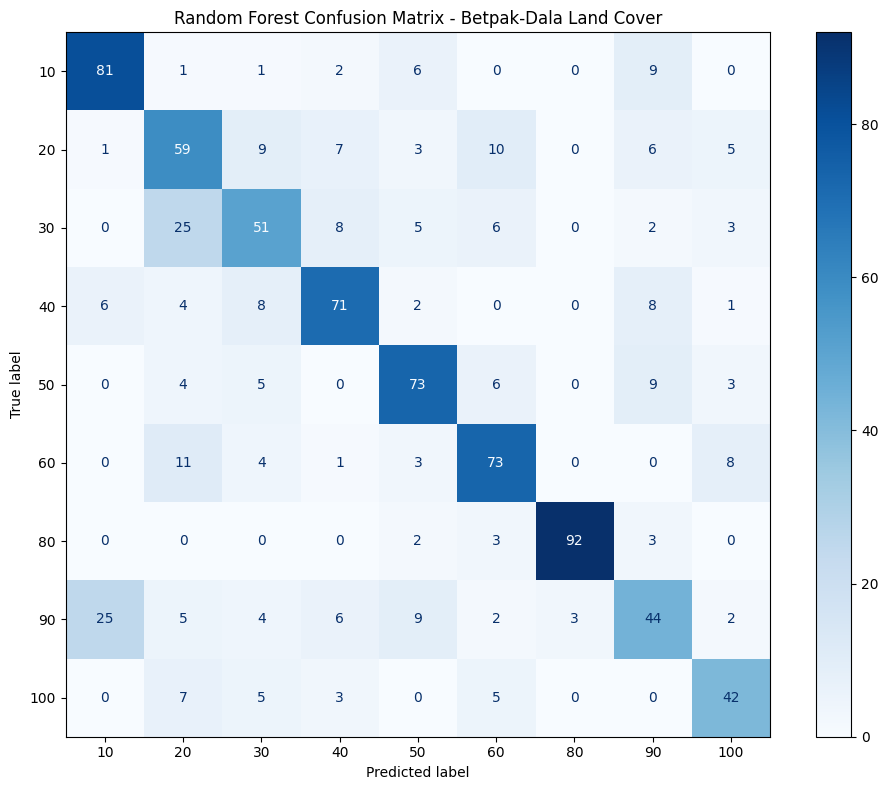

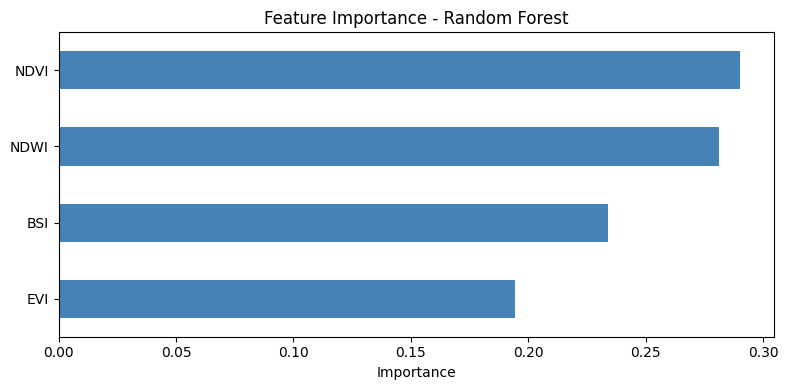

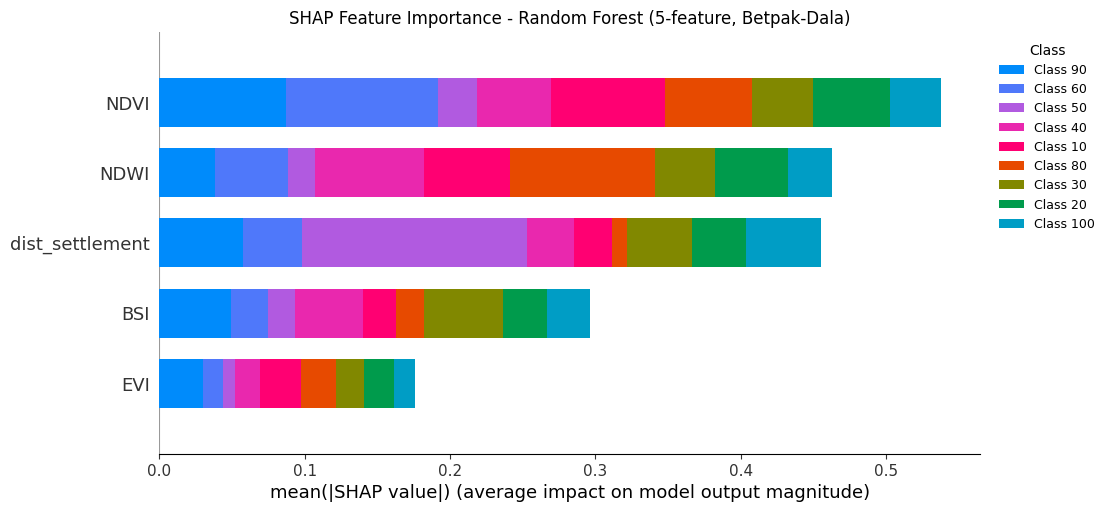

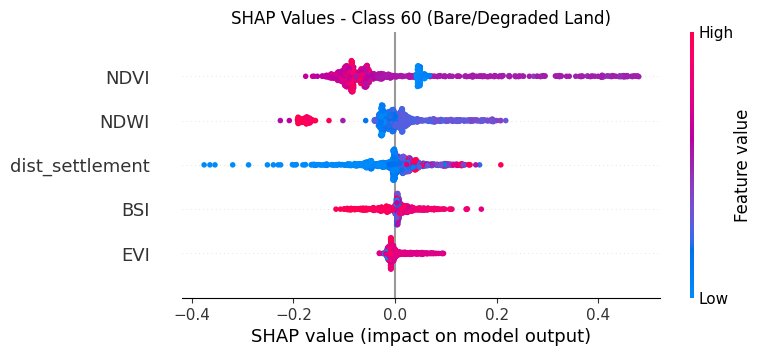

{
 "split_4f_RF": {
  "acc": 67.98143851508121,
  "wf1": 0.677958678195187,
  "mf1": 0.6774819043750938
 },
 "perclass_f1_4f": {
  "10": 0.76,
  "20": 0.55,
  "30": 0.55,
  "40": 0.72,
  "50": 0.72,
  "60": 0.71,
  "80": 0.94,
  "90": 0.49,
  "100": 0.67
 },
 "split_4f_XGB": {
  "acc": 66.24129930394432,
  "wf1": 0.6627490564657724,
  "mf1": 0.6612860614094855
 },
 "split_4f_SVM_scaled": {
  "acc": 56.148491879350345,
  "wf1": 0.5356728232987519,
  "mf1": 0.5130555263150267
 },
 "split_4f_SVM_unscaled": {
  "acc": 56.72853828306265,
  "wf1": 0.5404858821071729,
  "mf1": 0.5176653670848701
 },
 "split_5f_RF": {
  "acc": 73.31786542923435,
  "wf1": 0.7323597978126332,
  "mf1": 0.7332669995118262
 },
 "perclass_f1_5f": {
  "10": 0.76,
  "20": 0.56,
  "30": 0.6,
  "40": 0.75,
  "50": 0.88,
  "60": 0.75,
  "80": 0.95,
  "90": 0.59,
  "100": 0.75
 },
 "split_5f_XGB": {
  "acc": 72.50580046403712,
  "wf1": 0.725050965646665,
  "mf1": 0.7276617463685418
 },
 "split_5f_SVM_scaled": {
  "acc": 6

In [16]:
print('=== G. SHAP (5-feature RF, Betpak-Dala test split) ===')
sv = shap.TreeExplainer(rf5).shap_values(Xte5)
sv = np.stack(sv, axis=-1) if isinstance(sv, list) else sv
glob = pd.Series(np.abs(sv).mean(axis=(0, 2)), index=SPEC_D).sort_values(ascending=False)
c60 = CLASSES.index(60)
cls60 = pd.Series(np.abs(sv[:, :, c60]).mean(axis=0), index=SPEC_D).sort_values(ascending=False)
NUMS['shap_global'] = glob.round(4).to_dict(); NUMS['shap_c60'] = cls60.round(4).to_dict()
di = SPEC_D.index('dist_settlement')
rho = pd.Series(Xte5[:, di]).corr(pd.Series(sv[:, di, c60]), method='spearman')
NUMS['shap_c60_dist_spearman'] = round(rho, 3)
print('global:', NUMS['shap_global']); print('class 60:', NUMS['shap_c60'])
print('Spearman(dist value, SHAP for class 60):', NUMS['shap_c60_dist_spearman'],
      '(positive = farther from settlements pushes toward bare land)')

# ---------- Figures, same style and size as the originals ----------
LBL = [str(c) for c in CLASSES]
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(confusion_matrix(yte4, p4), display_labels=CLASSES).plot(ax=ax, cmap='Blues')
ax.set_title('Random Forest Confusion Matrix - Betpak-Dala Land Cover'); plt.tight_layout()
plt.savefig('fig1_confusion_matrix.png', dpi=100, bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
imp4.sort_values().plot(kind='barh', color='steelblue', ax=ax)
ax.set_title('Feature Importance - Random Forest'); ax.set_xlabel('Importance'); plt.tight_layout()
plt.savefig('fig2_feature_importance.png', dpi=100, bbox_inches='tight'); plt.show()

shap.summary_plot([sv[:, :, i] for i in range(len(CLASSES))], Xte5, feature_names=SPEC_D, plot_type='bar',
                  class_names=[f'Class {c}' for c in CLASSES], show=False, plot_size=(10, 5))
_ax = plt.gca(); _h, _l = _ax.get_legend_handles_labels()
_ax.legend(_h, _l, title='Class', bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False, fontsize=9)
plt.title('SHAP Feature Importance - Random Forest (5-feature, Betpak-Dala)')
plt.savefig('fig3_shap_global.png', dpi=100, bbox_inches='tight'); plt.show()

shap.summary_plot(sv[:, :, c60], Xte5, feature_names=SPEC_D, show=False)
plt.title('SHAP Values - Class 60 (Bare/Degraded Land)')
plt.savefig('fig4_shap_class60.png', dpi=100, bbox_inches='tight'); plt.show()

with zipfile.ZipFile('paper_figures_v3.zip', 'w') as z:
    for f in ['fig1_confusion_matrix.png', 'fig2_feature_importance.png', 'fig3_shap_global.png', 'fig4_shap_class60.png']:
        z.write(f)
def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, np.generic): return o.item()
    return o
print(json.dumps(_clean(NUMS), indent=1))
print('\nDONE. Download paper_figures_v3.zip from the Files panel (refresh it first).')